In [14]:
import os
import json
import csv

directory = 'data/odis_json/'

output_csv = 'players_phases_data.csv'

def process_match(file_path):
    with open(file_path, 'r') as f:
        match_data = json.load(f)
    
    match_date = match_data['info']['dates'][0]
    ground = match_data['info']['venue']
    
    player_data = {}
    
    # Teams and their players (extract from the JSON structure)
    teams_players = match_data['info']['players']
    player_registry = match_data['info']['registry']['people']  # Player ID map
    
    for inning in match_data['innings']:
        # Identify which team is batting
        batting_team = inning['team']
        opposition_team = match_data['info']['teams'][0] if match_data['info']['teams'][1] == batting_team else match_data['info']['teams'][1]
        
        for over in inning['overs']:
            for delivery in over['deliveries']:
                batter = delivery['batter']
                player_id = player_registry.get(batter, batter)  # Use registry to get player ID or fallback to name
                
                # Determine the player's team
                player_team = None
                for team, players in teams_players.items():
                    if batter in players:
                        player_team = team
                        break
                
                # Skip if the player is playing against their own team
                if player_team == opposition_team:
                    continue  # Skip this record
                
                # Initialize player data if not already done
                if player_id not in player_data:
                    player_data[player_id] = {
                        'Player Name': batter,
                        'Team': player_team,
                        'Powerplay': {'runs': 0, 'balls': 0, 'boundaries': 0},
                        'Middle Overs': {'runs': 0, 'balls': 0, 'boundaries': 0},
                        'Death Overs': {'runs': 0, 'balls': 0, 'boundaries': 0}
                    }
                
                # Determine the phase
                if over['over'] <= 10:
                    phase = 'Powerplay'
                elif over['over'] <= 40:
                    phase = 'Middle Overs'
                else:
                    phase = 'Death Overs'
                
                # Update player data for the phase
                runs = delivery['runs']['batter']
                player_data[player_id][phase]['runs'] += runs
                player_data[player_id][phase]['balls'] += 1
                
                # Check for boundaries, excluding non-boundary runs
                if (runs == 4 or runs == 6) and not delivery.get('non_boundary', False):
                    player_data[player_id][phase]['boundaries'] += 1
    
    # Calculate strike rates for each player and phase
    for player_id, data in player_data.items():
        for phase, phase_data in data.items():
            if phase not in ['Player Name', 'Team']:  # Skip the player name and team keys
                if phase_data['balls'] > 0:
                    phase_data['strike_rate'] = (phase_data['runs'] / phase_data['balls']) * 100
                else:
                    phase_data['strike_rate'] = 0
    
    return match_date, opposition_team, ground, player_data

# Write results to CSV
with open(output_csv, 'w', newline='') as csvfile:
    fieldnames = ['Player ID', 'Player Name', 'Team', 'Match Date', 'Opposition', 'Ground', 'Phase', 'Runs', 'Balls Faced', 'Strike Rate', 'Boundaries']
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
    
    writer.writeheader()
    
    for filename in os.listdir(directory):
        if filename.endswith('.json'):
            file_path = os.path.join(directory, filename)
            result = process_match(file_path)
            
            if result:  
                match_date, opposition, ground, player_data = result
                
                for player_id, data in player_data.items():
                    # Skip if opposition is the same as the player's team (like India vs India)
                    if data['Team'] == opposition:
                        continue

                    for phase, phase_data in data.items():
                        if phase not in ['Player Name', 'Team']:
                            writer.writerow({
                                'Player ID': player_id,
                                'Player Name': data['Player Name'],
                                'Team': data['Team'],
                                'Match Date': match_date,
                                'Opposition': opposition,
                                'Ground': ground,
                                'Phase': phase,
                                'Runs': phase_data['runs'],
                                'Balls Faced': phase_data['balls'],
                                'Strike Rate': phase_data['strike_rate'],
                                'Boundaries': phase_data['boundaries']
                            })

print("Processing complete. Data saved to", output_csv)


Processing complete. Data saved to players_phases_data.csv


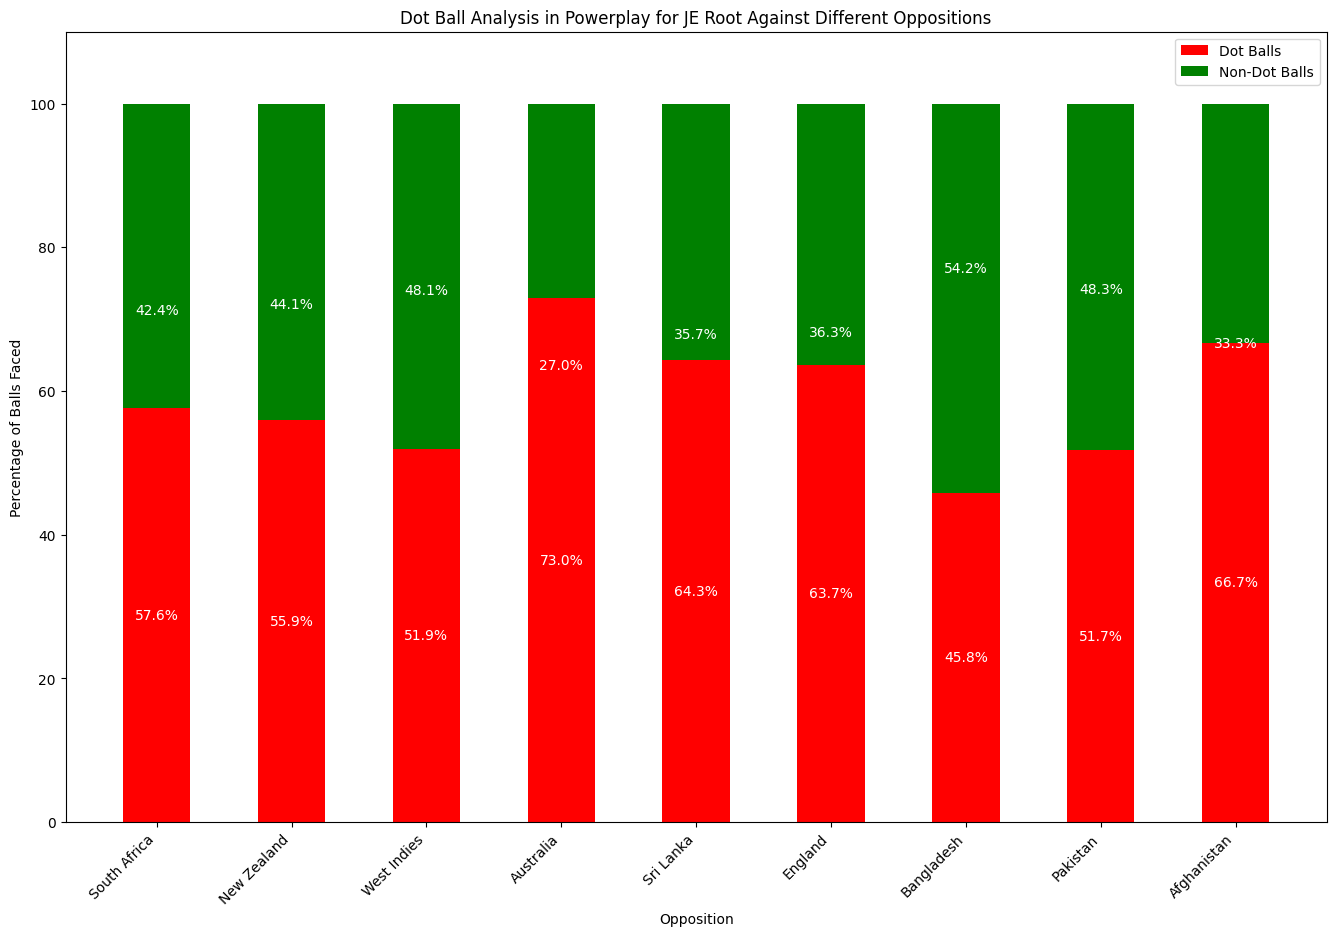

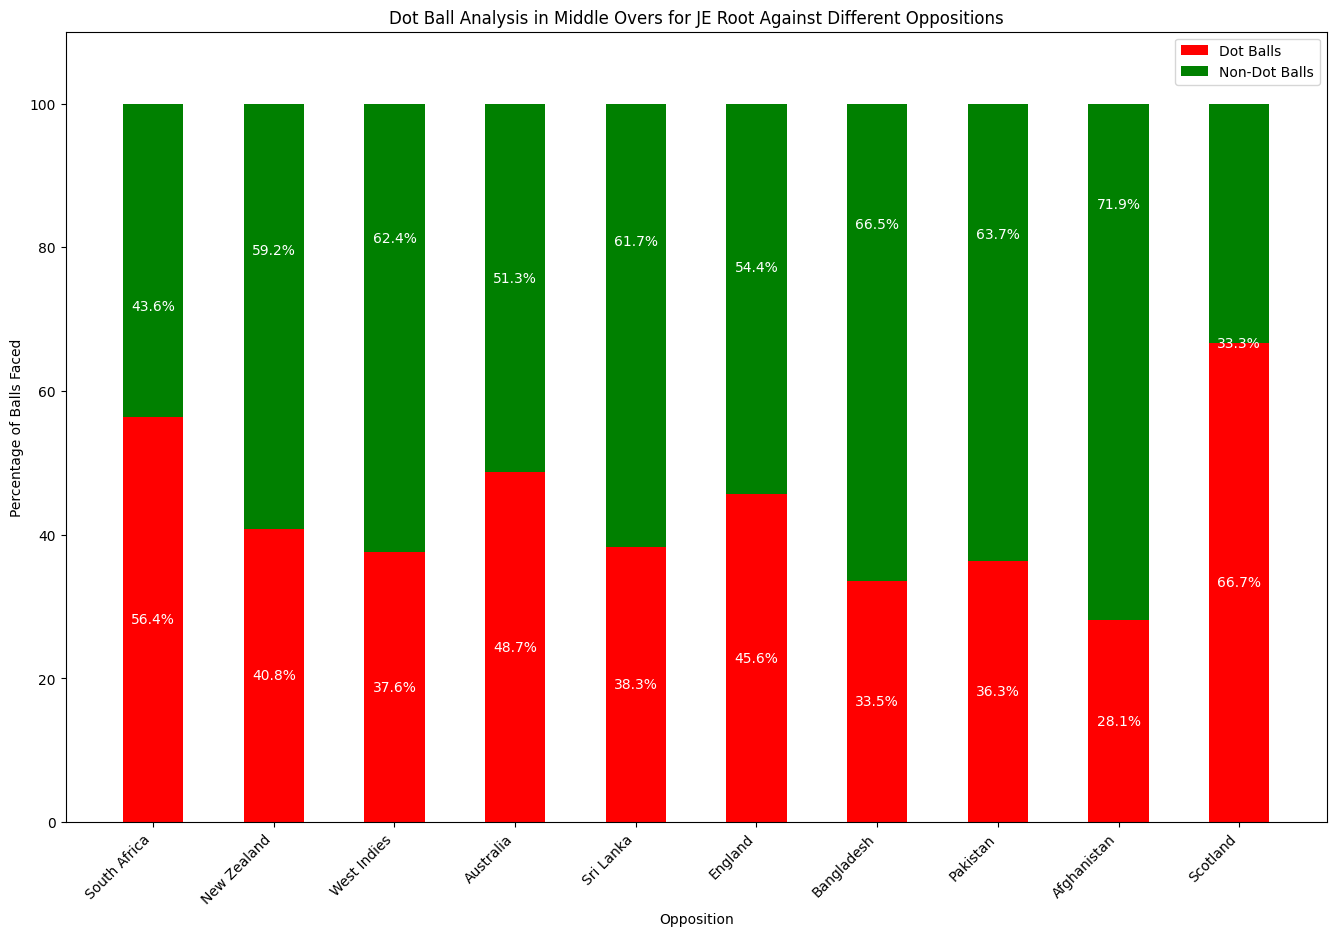

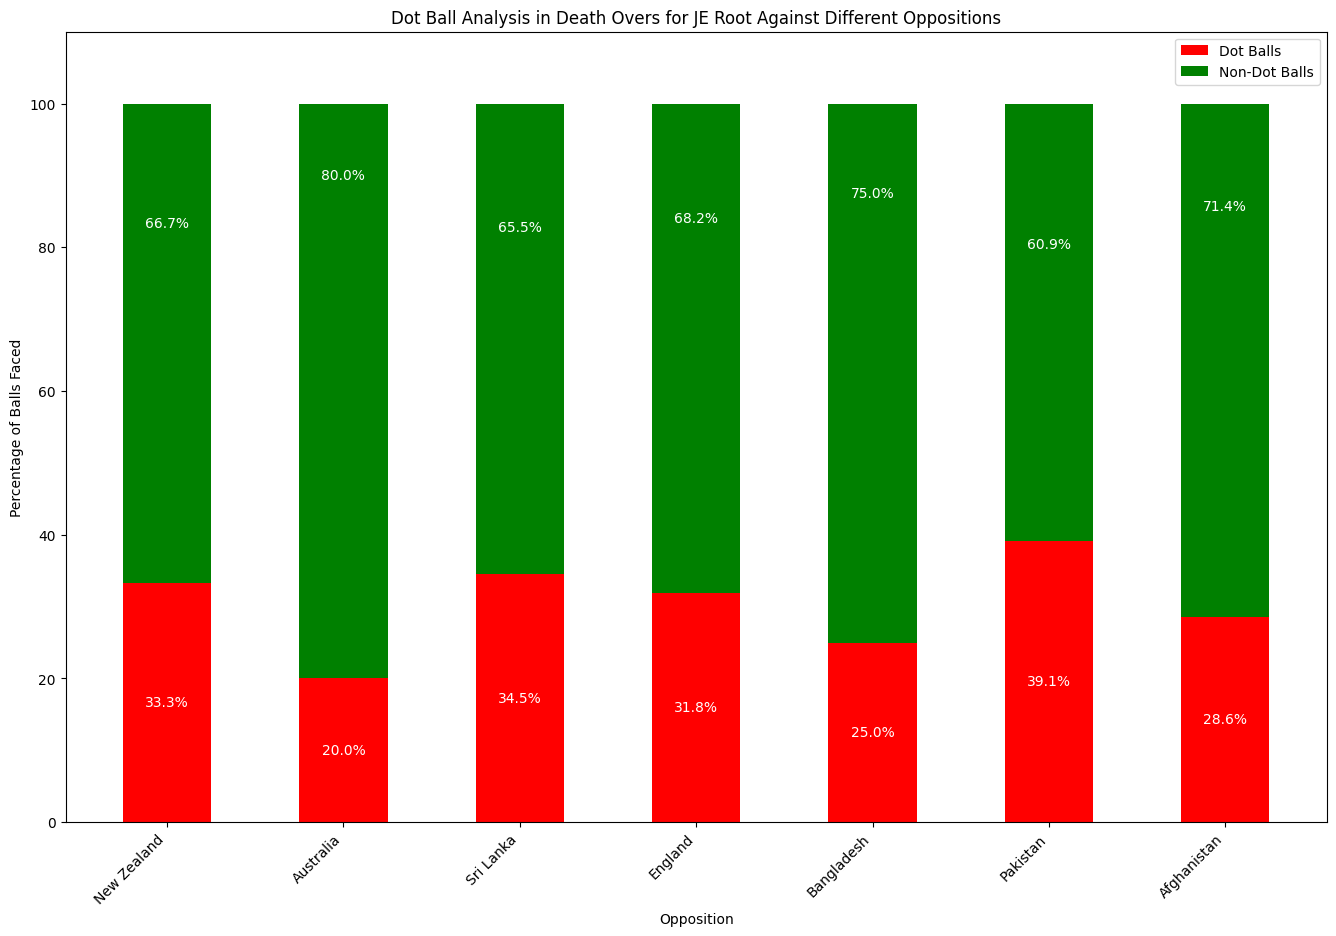

In [4]:
import os
import json
import matplotlib.pyplot as plt
from collections import defaultdict

# Directory containing the JSON files
directory = 'data/odis_json/'

opposition_data = defaultdict(lambda: {
    'Powerplay': {'dot_balls': 0, 'non_dot_balls': 0},
    'Middle Overs': {'dot_balls': 0, 'non_dot_balls': 0},
    'Death Overs': {'dot_balls': 0, 'non_dot_balls': 0}
})

def process_match(file_path, player_name):
    with open(file_path, 'r') as f:
        match_data = json.load(f)
    
    opposition = match_data['info']['teams'][0] if match_data['info']['teams'][1] == 'India' else match_data['info']['teams'][1]
    
    phases = {
        'Powerplay': {'runs': 0, 'balls': 0, 'boundaries': 0, 'dot_balls': 0},
        'Middle Overs': {'runs': 0, 'balls': 0, 'boundaries': 0, 'dot_balls': 0},
        'Death Overs': {'runs': 0, 'balls': 0, 'boundaries': 0, 'dot_balls': 0}
    }
    
    for inning in match_data['innings']:
        for over in inning['overs']:
            for delivery in over['deliveries']:
                if delivery['batter'] == player_name:  # Use the dynamic player name here
                    # Determine the phase
                    if over['over'] <= 10:
                        phase = 'Powerplay'
                    elif over['over'] <= 40:
                        phase = 'Middle Overs'
                    else:
                        phase = 'Death Overs'
                    
                    # Update phase data
                    runs = delivery['runs']['batter']
                    phases[phase]['runs'] += runs
                    phases[phase]['balls'] += 1
                    
                    # Check for boundaries, excluding non-boundary runs
                    if (runs == 4 or runs == 6) and not delivery.get('non_boundary', False):
                        phases[phase]['boundaries'] += 1
                    
                    # Check for dot balls (where no runs are scored by the batter)
                    if runs == 0:
                        phases[phase]['dot_balls'] += 1
    
    for phase, data in phases.items():
        opposition_data[opposition][phase]['dot_balls'] += data['dot_balls']
        opposition_data[opposition][phase]['non_dot_balls'] += data['balls'] - data['dot_balls']


def generate_charts(player_name):
    # Process all JSON files in the directory for the selected player
    for filename in os.listdir(directory):
        if filename.endswith('.json'):
            file_path = os.path.join(directory, filename)
            process_match(file_path, player_name)


    filtered_oppositions_powerplay = []
    filtered_oppositions_middle = []
    filtered_oppositions_death = []

    powerplay_dot_balls = []
    middle_dot_balls = []
    death_dot_balls = []

    powerplay_non_dot_balls = []
    middle_non_dot_balls = []
    death_non_dot_balls = []

    excluded_teams = {'Ireland', 'Netherlands', 'United Arab Emirates'}

    for opposition in opposition_data:
        if opposition in excluded_teams:
            continue

        total_powerplay_balls = opposition_data[opposition]['Powerplay']['dot_balls'] + opposition_data[opposition]['Powerplay']['non_dot_balls']
        total_middle_overs_balls = opposition_data[opposition]['Middle Overs']['dot_balls'] + opposition_data[opposition]['Middle Overs']['non_dot_balls']
        total_death_overs_balls = opposition_data[opposition]['Death Overs']['dot_balls'] + opposition_data[opposition]['Death Overs']['non_dot_balls']
        
    
        if total_powerplay_balls > 0:
            filtered_oppositions_powerplay.append(opposition)
            powerplay_dot_balls.append(opposition_data[opposition]['Powerplay']['dot_balls'] / total_powerplay_balls * 100)
            powerplay_non_dot_balls.append(opposition_data[opposition]['Powerplay']['non_dot_balls'] / total_powerplay_balls * 100)

        if total_middle_overs_balls > 0:
            filtered_oppositions_middle.append(opposition)
            middle_dot_balls.append(opposition_data[opposition]['Middle Overs']['dot_balls'] / total_middle_overs_balls * 100)
            middle_non_dot_balls.append(opposition_data[opposition]['Middle Overs']['non_dot_balls'] / total_middle_overs_balls * 100)

        if total_death_overs_balls > 0:
            filtered_oppositions_death.append(opposition)
            death_dot_balls.append(opposition_data[opposition]['Death Overs']['dot_balls'] / total_death_overs_balls * 100)
            death_non_dot_balls.append(opposition_data[opposition]['Death Overs']['non_dot_balls'] / total_death_overs_balls * 100)

    bar_width = 0.5  

    def plot_phase(phase_oppositions, phase_dot_balls, phase_non_dot_balls, phase_name):
        plt.figure(figsize=(14, 10))
        bars1 = plt.bar(phase_oppositions, phase_dot_balls, bar_width, color='red', label='Dot Balls')
        bars2 = plt.bar(phase_oppositions, phase_non_dot_balls, bar_width, bottom=phase_dot_balls, color='green', label='Non-Dot Balls')
        
        for i, bar in enumerate(bars1):
            plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2,
                     f'{phase_dot_balls[i]:.1f}%', ha='center', va='center', color='white', fontsize=10)
        
        for i, bar in enumerate(bars2):
            plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + phase_dot_balls[i] / 2,
                     f'{phase_non_dot_balls[i]:.1f}%', ha='center', va='center', color='white', fontsize=10)

        plt.xlabel('Opposition')
        plt.ylabel('Percentage of Balls Faced')
        plt.title(f'Dot Ball Analysis in {phase_name} for {player_name} Against Different Oppositions')
        plt.xticks(rotation=45, ha='right')
        plt.ylim(0, 110)  # Set the Y-axis limit to ensure bars don't overlap the top
        plt.legend()
        plt.tight_layout(pad=3.0)
        plt.show()

    # Powerplay
    plot_phase(filtered_oppositions_powerplay, powerplay_dot_balls, powerplay_non_dot_balls, 'Powerplay')

    # Middle Overs
    plot_phase(filtered_oppositions_middle, middle_dot_balls, middle_non_dot_balls, 'Middle Overs')

    # Death Overs
    plot_phase(filtered_oppositions_death, death_dot_balls, death_non_dot_balls, 'Death Overs')


player_name = input("Enter the player's name to analyze: ")
generate_charts(player_name)
